In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline


In [ ]:
df = pd.read_csv("hotel_bookings.csv")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 119390
Number of columns: 32


In [ ]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [ ]:
df.dtypes

,0
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [ ]:
df.shape

(119390, 32)

In [ ]:
df.nunique()

,0
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


In [ ]:
missing_values= df.isnull().sum()
print(missing_values)

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [ ]:
missing_values= df.isnull().sum()
missing_values= missing_values[missing_values>0]
print(missing_values)

children         4
country        488
agent        16340
company     112593
dtype: int64


In [ ]:
missing_percentage= (df.isnull().sum()/len(df))*100

missing_summary= pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

missing_summary= missing_summary[missing_summary['Missing Values']>0]

missing_summary= missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

missing_summary

,Missing Values,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


In [ ]:
df['children']= df['children'].fillna(0)
df['country']= df['country'].fillna('Unknown')
df['agent']= df['agent'].fillna(0)
df= df.drop(columns=['company'])

In [ ]:
print("Remaining missing values:")
print(df.isnull().sum()[df.isnull().sum()>0])

print("\nDataset shape after cleaning:")
print(df.shape)

Remaining missing values:
Series([], dtype: int64)

Dataset shape after cleaning:
(119390, 31)


In [ ]:
duplicate_count= df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 32001


In [ ]:
duplicate_percentage= (duplicate_count/len(df))*100
print("Duplicate percentage:", duplicate_percentage, "%")

Duplicate percentage: 26.803752408074377 %


In [ ]:
df[df.duplicated()].head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,0,No Deposit,240.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,1,No Deposit,250.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,0,No Deposit,250.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,0,No Deposit,240.0,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,0,No Deposit,240.0,0,Transient,109.80,0,3,Check-Out,2015-07-08


In [ ]:
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (87389, 31)


In [ ]:
print("Remaining duplicate rows:", df.duplicated().sum())

Remaining duplicate rows: 0


In [ ]:
print("Remaining missing values:")
print(df.isnull().sum()[df.isnull().sum()>0])

Remaining missing values:
Series([], dtype: int64)


In [ ]:
print("Final dataset shape:", df.shape)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

Final dataset shape: (87389, 31)
Total rows: 87389
Total columns: 31
Total missing values: 0
Total duplicate rows: 0


In [ ]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000
mean,0.274920,79.897195,2016.210313,26.837760,15.815698,1.005321,2.625548,1.875842,0.138644,0.010825,0.039078,0.030416,0.184005,0.271625,81.008193,0.749625,106.339070,0.084233,0.698589
std,0.446477,86.053274,0.686094,13.674352,8.835244,1.031935,2.053591,0.626490,0.455888,0.113601,0.193782,0.369160,1.731962,0.727270,109.946820,10.016130,55.013097,0.281544,0.831950
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,72.000000,0.000000,0.000000
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,98.100000,0.000000,0.000000
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,0.000000,134.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
summary_statistics= df.describe().T
summary_statistics

,count,mean,std,min,25%,50%,75%,max
is_canceled,87389.0,0.274920,0.446477,0.00,0.0,0.0,1.0,1.0
lead_time,87389.0,79.897195,86.053274,0.00,11.0,49.0,125.0,737.0
arrival_date_year,87389.0,2016.210313,0.686094,2015.00,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,87389.0,26.837760,13.674352,1.00,16.0,27.0,37.0,53.0
arrival_date_day_of_month,87389.0,15.815698,8.835244,1.00,8.0,16.0,23.0,31.0
stays_in_weekend_nights,87389.0,1.005321,1.031935,0.00,0.0,1.0,2.0,19.0
stays_in_week_nights,87389.0,2.625548,2.053591,0.00,1.0,2.0,4.0,50.0
adults,87389.0,1.875842,0.626490,0.00,2.0,2.0,2.0,55.0
children,87389.0,0.138644,0.455888,0.00,0.0,0.0,0.0,10.0
babies,87389.0,0.010825,0.113601,0.00,0.0,0.0,0.0,10.0


In [ ]:
adr= df['adr'].to_numpy()

print("Mean ADR:", np.mean(adr))
print("Median ADR:", np.median(adr))
print("Standard Deviation of ADR:", np.std(adr))
print("Minimum ADR:", np.min(adr))
print("Maximum ADR:", np.max(adr))

Mean ADR: 106.33907002025424
Median ADR: 98.1
Standard Deviation of ADR: 55.012782348180856
Minimum ADR: -6.38
Maximum ADR: 5400.0


In [ ]:
print("25th Percentile:", np.percentile(adr, 25))
print("50th Percentile:", np.percentile(adr, 50))
print("75th Percentile:", np.percentile(adr, 75))

25th Percentile: 72.0
50th Percentile: 98.1
75th Percentile: 134.0


In [ ]:
df.describe(include='object')

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,87389,87389,87389,87389,87389,87389,87389,87389,87389,87389,87389,87389
unique,2,12,5,178,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2016-02-14
freq,53426,11257,67971,27449,51615,69138,56546,46309,86244,71982,63364,211


In [ ]:
print("Hotel:")
print(df['hotel'].value_counts())

print("\nMeal:")
print(df['meal'].value_counts())

print("\nMarket Segment:")
print(df['market_segment'].value_counts())

print("\nCustomer Type:")
print(df['customer_type'].value_counts())

Hotel:
hotel
City Hotel      53426
Resort Hotel    33963
Name: count, dtype: int64

Meal:
meal
BB           67971
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64

Market Segment:
market_segment
Online TA        51615
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4208
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64

Customer Type:
customer_type
Transient          71982
Transient-Party    11724
Contract            3139
Group                544
Name: count, dtype: int64


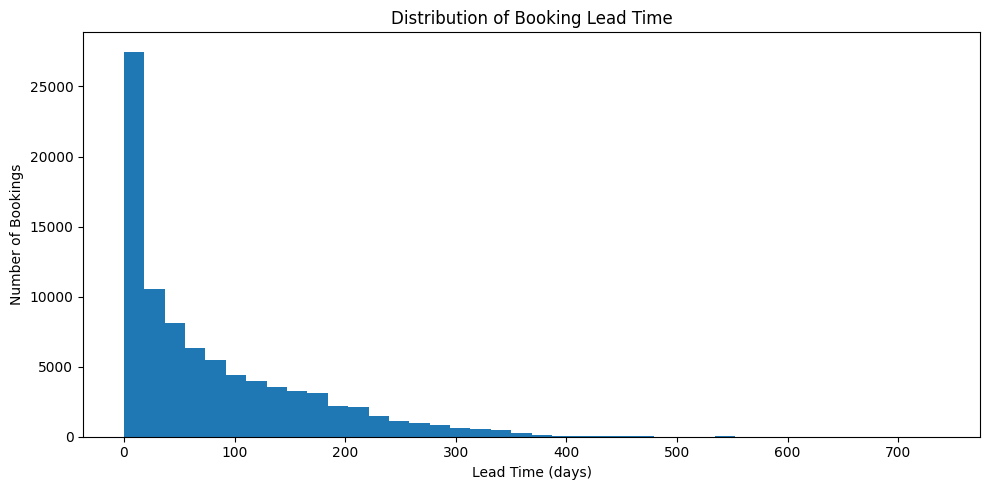

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df['lead_time'], bins=40)

plt.title("Distribution of Booking Lead Time")
plt.xlabel("Lead Time (days)")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

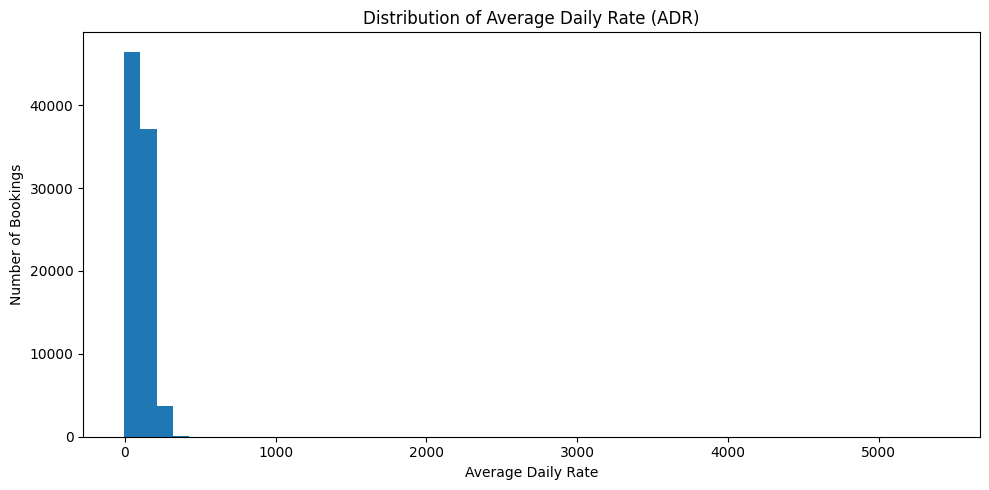

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df['adr'], bins=50)

plt.title("Distribution of Average Daily Rate (ADR)")
plt.xlabel("Average Daily Rate")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

In [ ]:
df['total_stay_nights']= (df['stays_in_weekend_nights'] + df['stays_in_week_nights'])

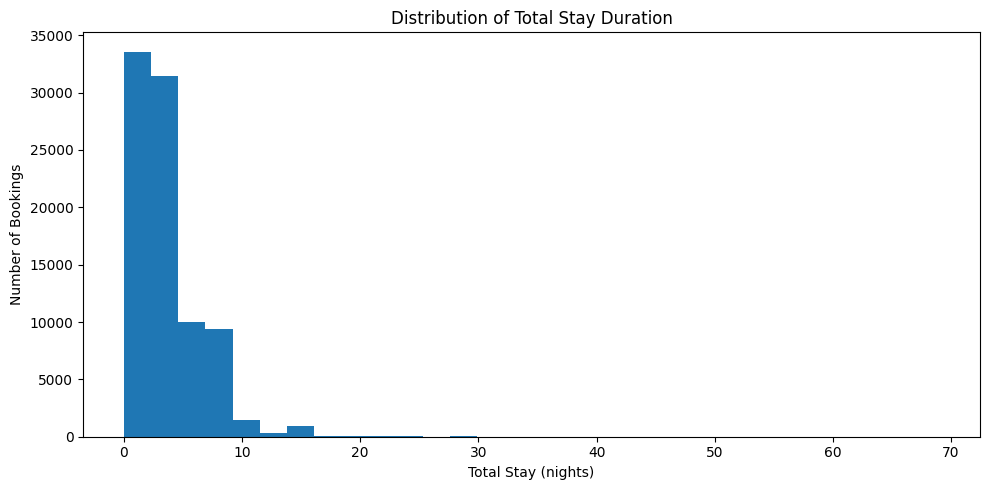

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(df['total_stay_nights'], bins=30)

plt.title("Distribution of Total Stay Duration")
plt.xlabel("Total Stay (nights)")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

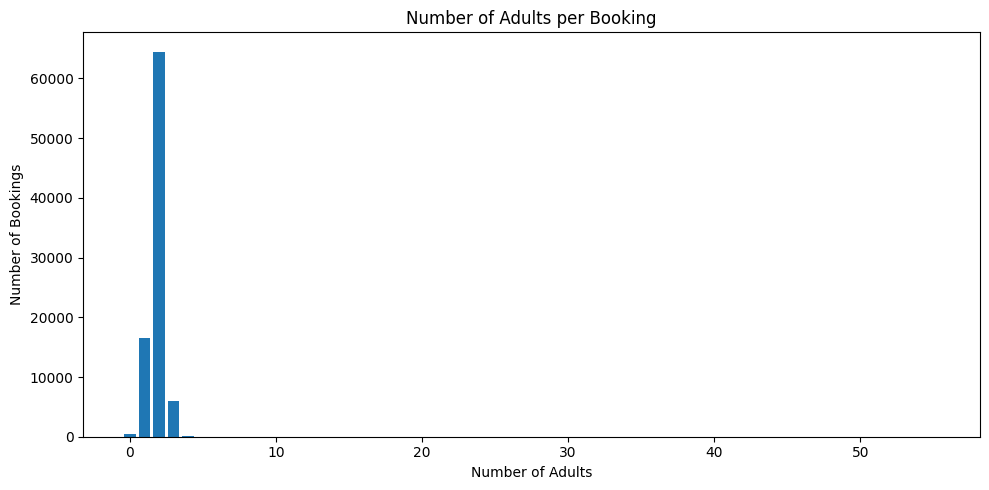

In [ ]:
adult_counts= df['adults'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(adult_counts.index,adult_counts.values)

plt.title("Number of Adults per Booking")
plt.xlabel("Number of Adults")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

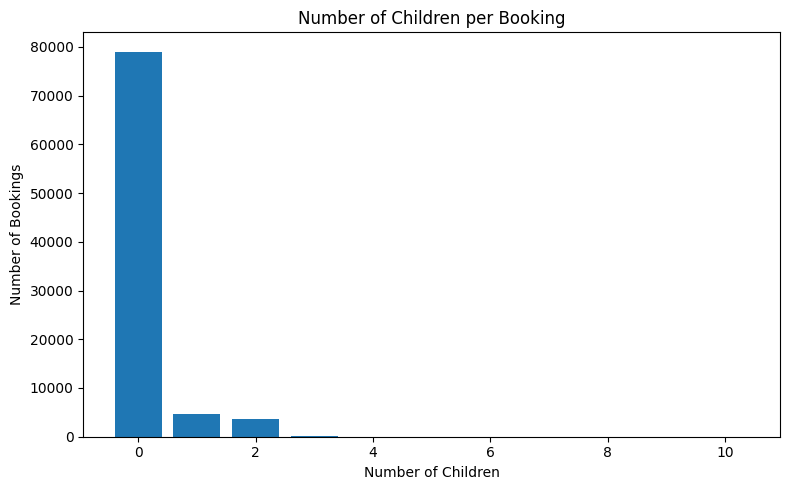

In [ ]:
children_counts= df['children'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(children_counts.index,children_counts.values)

plt.title("Number of Children per Booking")
plt.xlabel("Number of Children")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

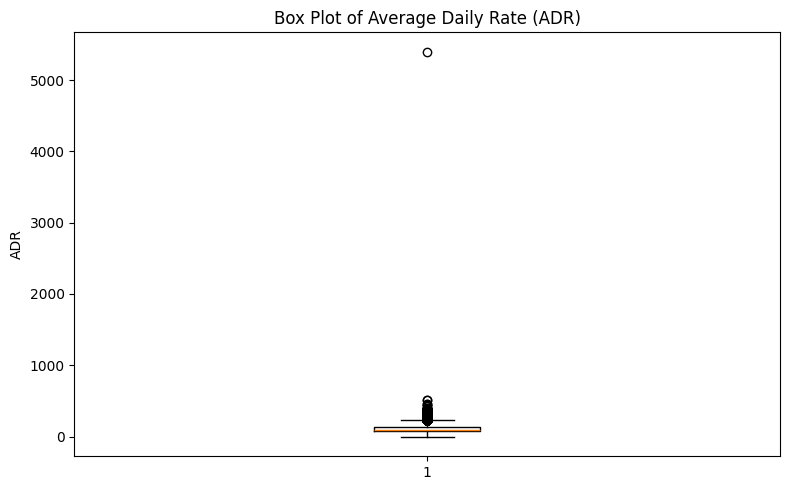

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['adr'])

plt.title("Box Plot of Average Daily Rate (ADR)")
plt.ylabel("ADR")

plt.tight_layout()
plt.show()

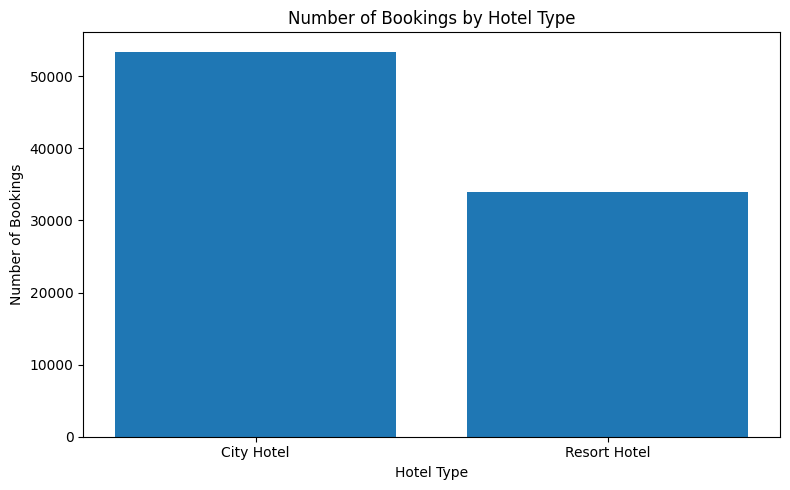

In [ ]:
hotel_counts= df['hotel'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(hotel_counts.index, hotel_counts.values)

plt.title("Number of Bookings by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

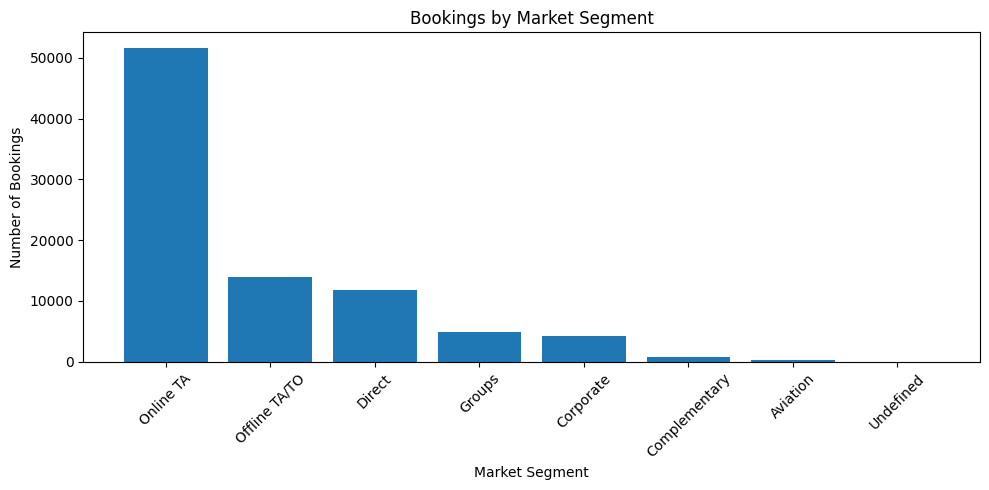

In [ ]:
market_counts= df['market_segment'].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(market_counts.index, market_counts.values)

plt.title("Bookings by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

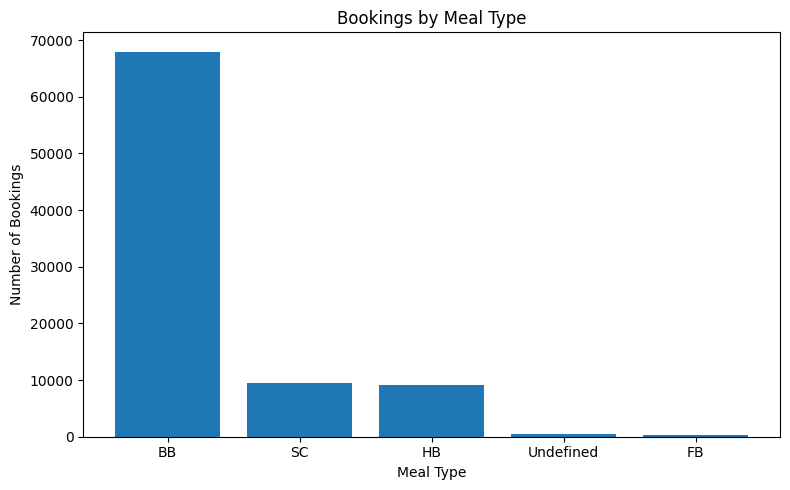

In [ ]:
meal_counts= df['meal'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(meal_counts.index, meal_counts.values)

plt.title("Bookings by Meal Type")
plt.xlabel("Meal Type")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

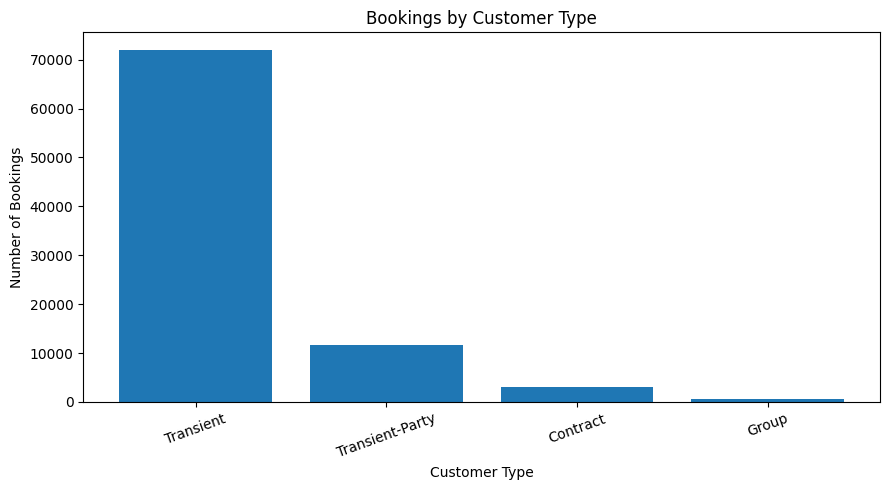

In [ ]:
customer_counts= df['customer_type'].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(customer_counts.index, customer_counts.values)

plt.title("Bookings by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

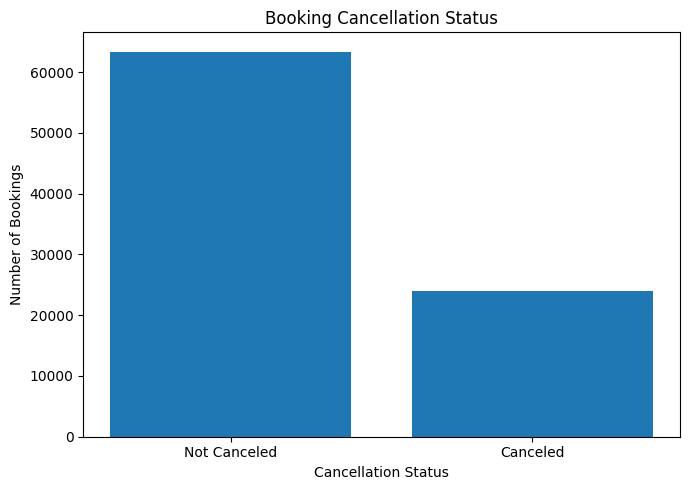

In [ ]:
cancellation_counts= df['is_canceled'].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(['Not Canceled', 'Canceled'],[cancellation_counts.get(0, 0),cancellation_counts.get(1, 0)])

plt.title("Booking Cancellation Status")
plt.xlabel("Cancellation Status")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

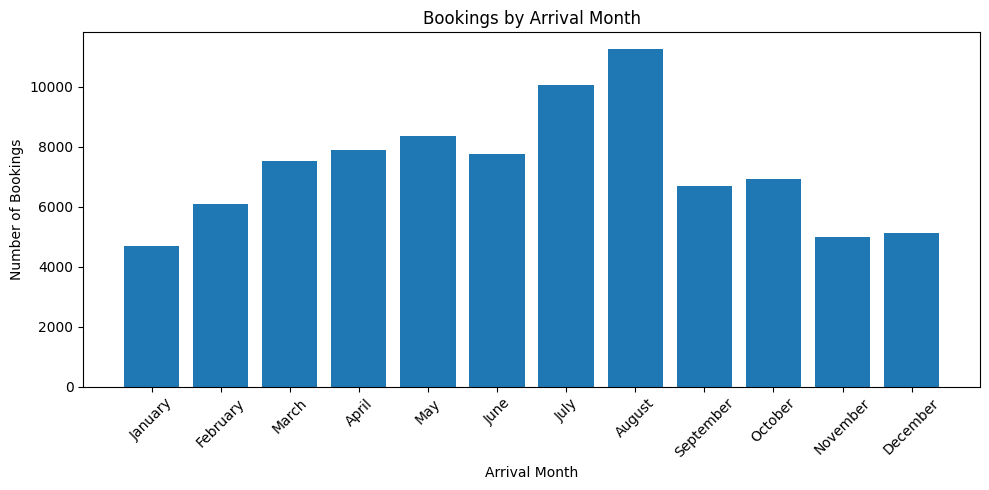

In [ ]:
month_order= [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings= (df['arrival_date_month'].value_counts().reindex(month_order))

plt.figure(figsize=(10, 5))

plt.bar(monthly_bookings.index, monthly_bookings.values)

plt.title("Bookings by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

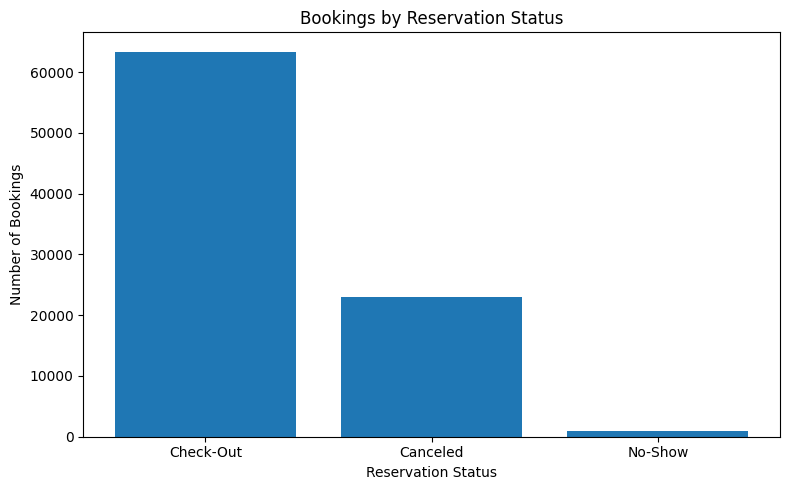

In [ ]:
status_counts= df['reservation_status'].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(status_counts.index, status_counts.values)

plt.title("Bookings by Reservation Status")
plt.xlabel("Reservation Status")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()

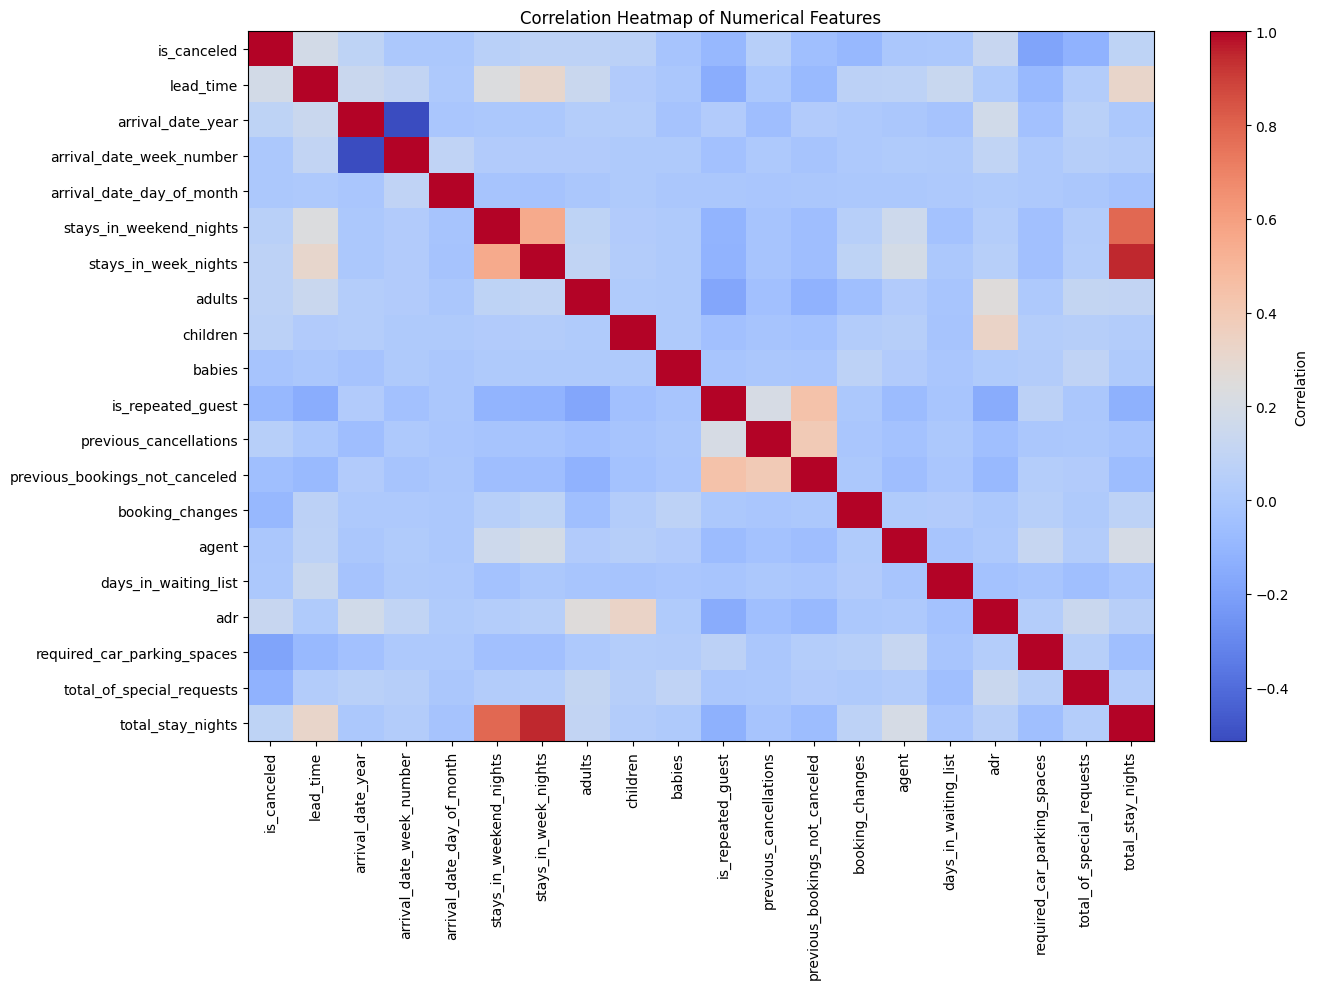

In [187]:
numeric_df= df.select_dtypes(include=np.number)
correlation_matrix= numeric_df.corr()

plt.figure(figsize=(14, 10))

plt.imshow(correlation_matrix, cmap='coolwarm', aspect='auto')
plt.colorbar(label='Correlation')

plt.xticks(range(len(correlation_matrix.columns)),correlation_matrix.columns,rotation=90)

plt.yticks(range(len(correlation_matrix.columns)),correlation_matrix.columns)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()